# 🫁 Lung Cancer Prediction Model

## 1. Problem Statement & Clinical Context
The goal of this module is to train a machine learning model to predict the presence of Lung Cancer based on behavioral and clinical patient data (e.g., age, smoking habits, chronic diseases). 

Because this is a medical screening tool, our primary evaluation metric must prioritize **Recall (Sensitivity)** to minimize False Negatives. Sending a sick patient home with a "Healthy" prediction is far more dangerous than sending a healthy patient for a secondary checkup.

## 2. Dataset Information
*   **Target Variable:** `LUNG_CANCER` (YES/NO)
*   **Features:** Categorical clinical flags (1 = NO, 2 = YES) and continuous demographics (Age).

## 3. Exploratory Data Analysis (EDA) & Data Sanity Audit
Before training any models, we audit the raw dataset for structural anomalies, hidden whitespace in column headers, missing values, and duplicate patient records.

In [1]:
import pandas as pd

In [2]:
# Load the row clinical dataset
df = pd.read_csv('datasets/lung_cancer.csv')

In [3]:
# Print raw column names as a list to expose hidden trailing/leading spaces
print("Raw Column Names (Watch the single quotes for hidden spaces):")
print(df.columns.tolist())

Raw Column Names (Watch the single quotes for hidden spaces):
['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING', 'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH', 'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']


In [4]:
# Preview the first 5 records
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


### 3.1 Schema Sanitization: Treating Trailing Whitespace & Inconsistent Separators
**Audit Finding:** Inspecting `df.columns.tolist()` revealed trailing whitespace in `'FATIGUE '` and `'ALLERGY '`, alongside inconsistent naming conventions (some features use underscores like `YELLOW_FINGERS`, while others use spaces like `CHRONIC DISEASE`).

**Treatment:** We strip all leading/trailing whitespace and standardize internal spaces to underscores (`UPPER_SNAKE_CASE`) so the trained model's `feature_names_in_` schema is uniform and bug-free for FastAPI inference.

In [5]:
# Strip leading/trailing spaces and standardize internal spaces to underscores
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Verify the sanitized column names
print("Sanitized Column Names:")
print(df.columns.tolist())

Sanitized Column Names:
['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN', 'LUNG_CANCER']


### 3.2 Data Integrity Audit: Missing Values, Data Types & Duplicate Records
Next, we check for `NaN` values, verify data types (`int64` vs `object`), and count exact duplicate rows to prevent **Train-Test Data Leakage** prior to splitting.

In [6]:
# 1. Check for missing (null) values across all columns
print("--- Missing Values Per Column ---")
print(df.isnull().sum())

--- Missing Values Per Column ---
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC_DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL_CONSUMING        0
COUGHING                 0
SHORTNESS_OF_BREATH      0
SWALLOWING_DIFFICULTY    0
CHEST_PAIN               0
LUNG_CANCER              0
dtype: int64


In [7]:
# 2. Check data types
print("\n--- Column Data Types ---")
print(df.dtypes)


--- Column Data Types ---
GENDER                   object
AGE                       int64
SMOKING                   int64
YELLOW_FINGERS            int64
ANXIETY                   int64
PEER_PRESSURE             int64
CHRONIC_DISEASE           int64
FATIGUE                   int64
ALLERGY                   int64
WHEEZING                  int64
ALCOHOL_CONSUMING         int64
COUGHING                  int64
SHORTNESS_OF_BREATH       int64
SWALLOWING_DIFFICULTY     int64
CHEST_PAIN                int64
LUNG_CANCER              object
dtype: object


In [8]:
# 3. Check for exact duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\n--- Duplicate Patient Records ---")
print(f"Total Exact Duplicate Rows Found: {duplicate_count} (out of { len(df) } rows)")


--- Duplicate Patient Records ---
Total Exact Duplicate Rows Found: 33 (out of 309 rows)


### 3.3 Treatment of Duplicate Records
**Audit Finding:** While there are `0` missing values across all 16 features, the dataset contains **33 exact duplicate rows** (~10.7% redundancy). Additionally, `GENDER` and `LUNG_CANCER` are stored as categorical `object` strings.

**Treatment:** We drop all 33 duplicate records and reset the DataFrame index prior to any splitting or oversampling so identical records cannot leak across the training and testing sets.

In [9]:
# Drop exact duplicate rows and reset index cleanly from 0 to N-1
df = df.drop_duplicates().reset_index(drop=True)

print(f"Cleaned Dataset Shape: {df.shape[0]} unique rows, {df.shape[1]} columns")
print(f"Remaining Duplicates: {df.duplicated().sum()}")

Cleaned Dataset Shape: 276 unique rows, 16 columns
Remaining Duplicates: 0


### 3.4 Target Class Imbalance Analysis
**Goal:** Visualize the distribution of our target variable (`LUNG_CANCER`). Medical datasets frequently suffer from class imbalance. If the minority class is too small, the model may overfit to the majority class, requiring intervention (like SMOTE) before training.

C:\Users\rajde\AppData\Local\Temp\ipykernel_2288\1475605833.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


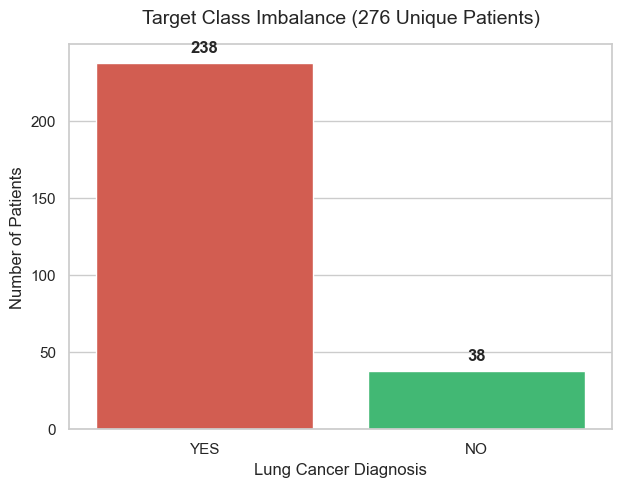


--- Percentage Breakdown ---
LUNG_CANCER
YES    86.23%
NO     13.77%
Name: proportion, dtype: object


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, professional style
sns.set_theme(style="whitegrid")

# Create the figure
plt.figure(figsize=(7, 5))

# Plot the counts with custom colors
ax = sns.countplot(
    data=df, 
    x='LUNG_CANCER', 
    palette={'YES': '#e74c3c', 'NO': '#2ecc71'} # Red for YES, Green for NO
)

plt.title('Target Class Imbalance (276 Unique Patients)', fontsize=14, pad=15)
plt.xlabel('Lung Cancer Diagnosis', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)

# Annotate exact counts on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), 
                textcoords='offset points', fontsize=12, fontweight='bold')

plt.show()

# Print exact percentages
print("\n--- Percentage Breakdown ---")
print((df['LUNG_CANCER'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

### 3.5 Binary Encoding & Feature Normalization
**Goal:** ML models require numeric inputs. We must convert text (`YES`/`NO`, `M`/`F`) to binary `1`/`0`. Additionally, the original Kaggle dataset encodes clinical flags (like `SMOKING`, `ANXIETY`) as `1` (NO) and `2` (YES). We will subtract `1` from these columns to normalize the entire dataset to a standard `0/1` boolean format, matching our JSON API contract.

In [11]:
# 1. Map String categorical variables to 1 and 0
df['LUNG_CANCER'] = df['LUNG_CANCER'].map({'YES': 1, 'NO': 0})
df['GENDER'] = df['GENDER'].map({'M': 1, 'F': 0})

In [12]:
# 2. Identify clinical flag columns (all columns except AGE, GENDER, LUNG_CANCER)
clinical_flags = [col for col in df.columns if col not in ['AGE', 'GENDER', 'LUNG_CANCER']]

In [13]:
# 3. Apply a -1 mathematical shift to transform 1/2 into 0/1
df[clinical_flags] = df[clinical_flags] - 1

In [14]:
# Verify the transformation
print("--- Data Snapshot After 0/1 Normalization ---")
df.head()

--- Data Snapshot After 0/1 Normalization ---


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0
3,1,63,1,1,1,0,0,0,0,0,1,0,0,1,1,0
4,0,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0


## 4. Model Preprocessing
### 4.1 Feature Separation & Stratified Train-Test Split
**Goal:** Isolate 20% of the raw, real patient data as an unseen Testing Set *before* applying synthetic oversampling. 
**Method:** We use `stratify=y` to ensure the severe 86/14 class imbalance is proportionally maintained in both the Train and Test sets, preventing a scenario where the minority class is entirely missing from the testing vault.

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
# 1. Separate Features (X) and Target (y)
X = df.drop(columns=['LUNG_CANCER'])
y = df['LUNG_CANCER']

In [17]:
# 2. Perform Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, # Ensures we get the exact same split every time we run the notebook
    stratify=y       # Preserves the 86/14 ratio in both sets
)

In [18]:
print(f"X_train Shape: {X_train.shape} (Will be sent to SMOTE)")
print(f"X_test Shape: {X_test.shape}  (Locked in the vault for final testing)\n")

X_train Shape: (220, 15) (Will be sent to SMOTE)
X_test Shape: (56, 15)  (Locked in the vault for final testing)



In [19]:
print("--- y_train Class Distribution Before SMOTE ---")
print(y_train.value_counts())

--- y_train Class Distribution Before SMOTE ---
LUNG_CANCER
1    190
0     30
Name: count, dtype: int64


### 4.2 Handling Class Imbalance with SMOTE
**Goal:** Balance the training dataset to a 50/50 ratio to prevent model bias towards the majority class (YES).   

**Method:** We apply ```Synthetic Minority Over-sampling Technique``` (SMOTE) strictly to the training data. SMOTE generates new, synthetic minority class samples by interpolating between existing minority instances. *(Note: Tree-based models are scale-invariant, so we intentionally bypass feature scaling to preserve clinical interpretability).*

In [20]:
from imblearn.over_sampling import SMOTE

In [21]:
# Initialize SMOTE
smote = SMOTE(random_state=42)

In [22]:
# Apply SMOTE strictly to the training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [23]:
print(f"Original X_train shape: {X_train.shape}")
print(f"SMOTE X_train shape: {X_train_smote.shape}\n")

Original X_train shape: (220, 15)
SMOTE X_train shape: (380, 15)



In [24]:
print("--- y_train Class Distribution AFTER SMOTE ---")
print(y_train_smote.value_counts())

--- y_train Class Distribution AFTER SMOTE ---
LUNG_CANCER
1    190
0    190
Name: count, dtype: int64


### 5.2 Deep Functional Hyperparameter Tuning (ROC AUC Optimization)
**Goal:** Empirically discover the optimal `max_depth` for our Random Forest.
**Method:** We use a 4-layer functional composition architecture to iterate through depths 3 to 15. The models are evaluated based on **Recall** (to minimize medical false negatives) and **ROC AUC** (to measure overall discriminative power).

In [60]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, precision_score
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

In [61]:
# Layer 1: The Math Layer
def calculate_core_metrics(y_true, y_pred, y_prob) -> dict:
    """Calculates evaluation metrics from raw arrays."""
    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Recall': round(recall_score(y_true, y_pred), 4), # Sensitivity
        'Precision': round(precision_score(y_true, y_pred), 4),
        'ROC_AUC': round(roc_auc_score(y_true, y_prob), 4)
    }

In [62]:
# Layer 2: The Inference Layer
def evaluate_single_model(model, X_test, y_test) -> dict:
    """Generates predictions and probabilities, then delegates to the Math Layer."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] # Probability of Class 1 (YES)
    return calculate_core_metrics(y_test, y_pred, y_prob)

In [63]:
# Layer 3: The Engine Layer
def train_and_score_depth(depth: int, X_train, y_train, X_test, y_test) -> dict:
    """Initializes and trains a model for a specific depth, then delegates to Inference."""
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # Get metrics from Layer 2
    metrics = evaluate_single_model(rf, X_test, y_test)
    metrics['Max_Depth'] = depth # Tag the result with the depth used
    return metrics

In [64]:
# Layer 4: The Orchestrator Layer
def hyperparameter_tuning_loop(min_depth: int, max_depth: int, X_train, y_train, X_test, y_test):
    """Loops through depths, collects results, and prints the leaderboard."""
    print(f"Starting tuning loop for depths {min_depth} to {max_depth}...\n")
    results = []
    
    for depth in range(min_depth, max_depth + 1):
        depth_metrics = train_and_score_depth(depth, X_train, y_train, X_test, y_test)
        results.append(depth_metrics)
        
    leaderboard = pd.DataFrame(results)
    
    # FIX: Changed 'precision' to 'Precision' to match the dictionary key exactly
    leaderboard = leaderboard[['Max_Depth', 'ROC_AUC', 'Recall', 'Precision', 'Accuracy']]
    leaderboard = leaderboard.sort_values(by='ROC_AUC', ascending=False).reset_index(drop=True)
    
    print("--- Final Model Leaderboard ---")
    display(leaderboard) 
    
    return leaderboard

In [65]:
# Run the 4-Layer Architecture
results_df = hyperparameter_tuning_loop(3, 15, X_train_smote, y_train_smote, X_test, y_test)

Starting tuning loop for depths 3 to 15...

--- Final Model Leaderboard ---


,Max_Depth,ROC_AUC,Recall,Precision,Accuracy
0,3,0.9766,0.9792,0.9400,0.9286
1,5,0.9740,0.9792,0.9400,0.9286
2,6,0.9714,0.9792,0.9400,0.9286
3,4,0.9688,0.9792,0.9400,0.9286
4,8,0.9688,0.9583,0.9388,0.9107
5,15,0.9688,0.9583,0.9388,0.9107
6,9,0.9688,0.9583,0.9388,0.9107
7,14,0.9688,0.9583,0.9388,0.9107
8,13,0.9688,0.9583,0.9388,0.9107
9,7,0.9661,0.9583,0.9388,0.9107


### 5.3 Algorithm Benchmarking Tournament
**Goal:** Prove empirically that our chosen algorithm is the best fit for this clinical dataset.   

**Method:** We pit our tuned Random Forest (`max_depth=3`) against Gradient Boosting, Logistic Regression, and Support Vector Machines (SVM). 
*Note on ML Rigor: Because LR and SVM are distance-based algorithms, we apply `StandardScaler` inside the loop to ensure a fair mathematical comparison, preventing numerical features like `AGE` from dominating boolean features.*

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler

In [67]:
# 1. Scale the data to ensure a "Fair Fight" for SVM and Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

In [68]:
# 2. Define our tournament contenders
models = {
    "Random Forest (Depth=3)": RandomForestClassifier(max_depth=3, n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

In [69]:
tournament_results = []

print("Starting Algorithm Tournament...\n")

Starting Algorithm Tournament...



In [70]:
# 3. Run the loop
for name, model in models.items():
    # Train the model on the scaled SMOTE data
    model.fit(X_train_scaled, y_train_smote)
    
    # Generate predictions on the scaled vault data
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Reuse our Layer 1 Math function from the previous cell!
    metrics = calculate_core_metrics(y_test, y_pred, y_prob)
    metrics['Algorithm'] = name
    tournament_results.append(metrics)

In [73]:
# 4. Format and display the Leaderboard
algo_leaderboard = pd.DataFrame(tournament_results)
algo_leaderboard = algo_leaderboard[['Algorithm', 'ROC_AUC', 'Recall', 'Precision', 'Accuracy']]
algo_leaderboard = algo_leaderboard.sort_values(by='ROC_AUC', ascending=False).reset_index(drop=True)

In [74]:
print("--- Final Algorithm Tournament Leaderboard ---")
display(algo_leaderboard)

--- Final Algorithm Tournament Leaderboard ---


,Algorithm,ROC_AUC,Recall,Precision,Accuracy
0,Random Forest (Depth=3),0.9766,0.9792,0.9400,0.9286
1,Gradient Boosting,0.9531,0.9375,0.9184,0.8750
2,Logistic Regression,0.9505,0.9583,0.9200,0.8929
3,Support Vector Machine,0.9479,0.9583,0.9020,0.8750


## 6. Explainable AI (XAI) & Model Serialization
### 6.1 Feature Importance Visualization
**Goal:** Extract and visualize the internal decision-making weights of our production model.   
**Method:** We train our finalized `RandomForestClassifier(max_depth=3)` on the unscaled `X_train_smote` data (preserving readable clinical thresholds). We then extract `feature_importances_` and plot them using Seaborn to provide transparent, interpretable diagnostic criteria for medical staff.

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [76]:
# 1. Lock in and train the FINAL production model on UNSCALED data
final_rf_model = RandomForestClassifier(max_depth=3, n_estimators=100, random_state=42, n_jobs=-1)
final_rf_model.fit(X_train_smote, y_train_smote)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [77]:
# 2. Extract Feature Importances from the trained brain
importances = final_rf_model.feature_importances_
feature_names = X_train_smote.columns

In [78]:
# 3. Create a DataFrame and sort it from most to least important
feature_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_df = feature_df.sort_values(by='Importance', ascending=False)

In [79]:
# 4. Plot the Explainable AI (XAI) Bar Chart
plt.figure(figsize=(10, 8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

C:\Users\rajde\AppData\Local\Temp\ipykernel_2288\520748275.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_df, palette='viridis')


XAI Chart successfully saved to: 'assets\xai_feature_importances.png'


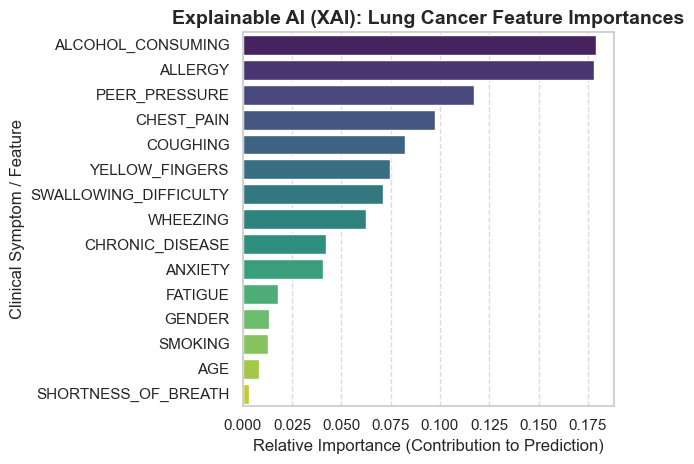

In [93]:
# 'viridis' provides a clean, professional, colorblind-friendly medical palette
sns.barplot(x='Importance', y='Feature', data=feature_df, palette='viridis')

plt.title('Explainable AI (XAI): Lung Cancer Feature Importances', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance (Contribution to Prediction)', fontsize=12)
plt.ylabel('Clinical Symptom / Feature', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# 4. SAVE THE CANVAS (Before showing it)
export_dir = 'assets'
os.makedirs(export_dir, exist_ok=True)
xai_file_path = os.path.join(export_dir, 'xai_feature_importances.png')

plt.savefig(xai_file_path, dpi=300, bbox_inches='tight')
print(f"XAI Chart successfully saved to: '{xai_file_path}'")

plt.show()

### 6.2 Decision Logic Flowchart & Asset Export
**Goal:** Expose the exact IF/ELSE clinical rules the model uses to classify patients, and safely store the output.     
**Method:** We use Python's `os` module to generate an `assets/` directory. We then extract a single estimator from our Random Forest ensemble, map its routing logic using `plot_tree`, and export this as a high-resolution `.png` file into our isolated assets folder.

In [84]:
import os
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [85]:
# 1. Create a dedicated folder for our exported visuals
export_dir = 'assets'
os.makedirs(export_dir, exist_ok=True)

In [86]:
# 2. Extract a single representative tree from the forest
single_tree = final_rf_model.estimators_[0]

In [87]:
# 3. Set up a massive canvas for readability
plt.figure(figsize=(24, 12))

<Figure size 2400x1200 with 0 Axes>

<Figure size 2400x1200 with 0 Axes>

Folder 'assets/' confirmed.
Flowchart rendered and saved securely to 'assets\decision_tree_flowchart.png'!


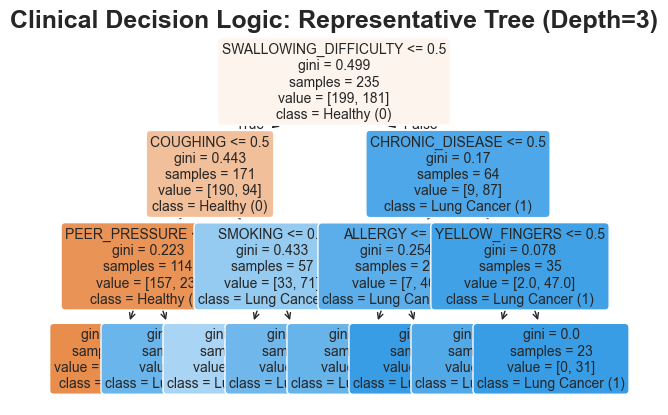

In [88]:
# 4. Draw the flowchart
plot_tree(
    single_tree, 
    feature_names=feature_names, 
    class_names=['Healthy (0)', 'Lung Cancer (1)'], 
    filled=True, 
    rounded=True, 
    fontsize=10,
    proportion=False
)

plt.title('Clinical Decision Logic: Representative Tree (Depth=3)', fontsize=18, fontweight='bold')

# 5. Save the high-res image directly to the assets folder!
file_path = os.path.join(export_dir, 'decision_tree_flowchart.png')
plt.savefig(file_path, dpi=300, bbox_inches='tight')

print(f"Folder '{export_dir}/' confirmed.")
print(f"Flowchart rendered and saved securely to '{file_path}'!")
plt.show()